<center>Практическое задание</center>

1. Написать архитектуру MLP на более 5 слоёв и обучить модель на наборе данных Fashin MNIST (есть и в PyTorch)
2. Перепробовать различные методы регуляризации из пройденных на семинаре и отобрать наилучшую комбинацию в вашем случае

<center><span style='color:blue'>Задание 1</span>

In [1]:
import torch
from torchvision.datasets import FashionMNIST
from torchvision import transforms
from torch import nn
from torch.utils.data import DataLoader

<span style='color:grey'>FashionMNIST</span> - содержит ч/б изображение 28 x 28 пикселей, содержит 10 типов: 

0. T-shirt/top
1. Trouser
2. Pullover
3. Dress
4. Coat
5. Sandal
6. Shirt
7. Sneaker
8. Bag
9. Ankle boot

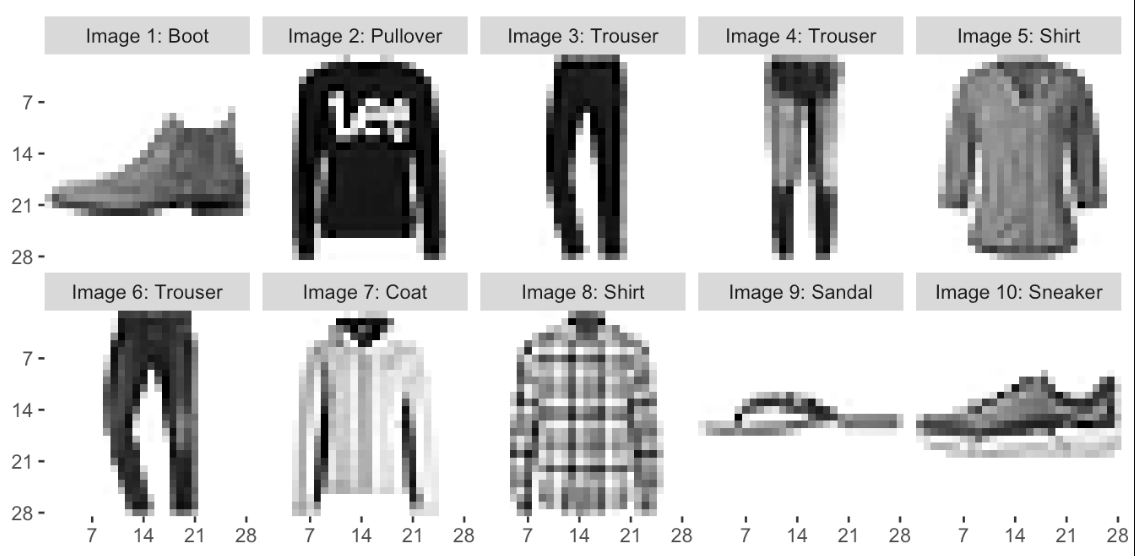

In [2]:
train_dataset = FashionMNIST(root='/simpleNNFashion', train=True, download=True, transform=transforms.ToTensor())
test_dataset = FashionMNIST(root='/simpleNNFashion', train=False, download=True, transform=transforms.ToTensor())

In [83]:
train_dataset

Dataset FashionMNIST
    Number of datapoints: 60000
    Root location: /simpleNNFashion
    Split: Train
    StandardTransform
Transform: ToTensor()

In [3]:
torch.manual_seed(42)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
valid_loader = DataLoader(test_dataset, batch_size=64)

In [106]:
class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.layer1 = nn.Linear(28 * 28 * 1, 512)
        self.layer2 = nn.Linear(512, 256)
        self.layer3 = nn.Linear(256, 128)
        self.layer4 = nn.Linear(128, 64)
        self.layer5 = nn.Linear(64, 32)
        self.layer6 = nn.Linear(32, 10)
        self.activation = nn.ReLU()
        self.flatten = nn.Flatten()

    def forward(self, x):
        x = self.activation(self.layer1(self.flatten(x)))
        x = self.activation(self.layer2(x))
        x = self.activation(self.layer3(x))
        x = self.activation(self.layer4(x))
        x = self.activation(self.layer5(x))
        x = self.layer6(x)
        return x

In [107]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device: ', device)
model = MLP()
model.to(device)

Device:  cuda


MLP(
  (layer1): Linear(in_features=784, out_features=512, bias=True)
  (layer2): Linear(in_features=512, out_features=256, bias=True)
  (layer3): Linear(in_features=256, out_features=128, bias=True)
  (layer4): Linear(in_features=128, out_features=64, bias=True)
  (layer5): Linear(in_features=64, out_features=32, bias=True)
  (layer6): Linear(in_features=32, out_features=10, bias=True)
  (activation): ReLU()
  (flatten): Flatten(start_dim=1, end_dim=-1)
)

In [108]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

In [109]:
import numpy as np


EPOCHS = 20

for epoch in range(EPOCHS):
    print('Starting epoch: ', epoch + 1)
    model.train()
    train_loss = []
    valid_loss = []
    for data, targets in train_loader:
        data, targets = data.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = model(data)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        train_loss.append(loss.item())

    model.eval()
    with torch.inference_mode():
        for data, targets in valid_loader:
            data, targets = data.to(device), targets.to(device)
            outputs = model(data)
            loss = criterion(outputs, targets)
            valid_loss.append(loss.item())
            print(f'Epoch {epoch + 1} train loss: {np.mean(train_loss)} validation loss: {np.mean(valid_loss)}')


Starting epoch:  1
Epoch 1 train loss: 0.7887079688151677 validation loss: 0.6152685880661011
Epoch 1 train loss: 0.7887079688151677 validation loss: 0.47455428540706635
Epoch 1 train loss: 0.7887079688151677 validation loss: 0.45989611744880676
Epoch 1 train loss: 0.7887079688151677 validation loss: 0.4782445654273033
Epoch 1 train loss: 0.7887079688151677 validation loss: 0.4811441659927368
Epoch 1 train loss: 0.7887079688151677 validation loss: 0.47202075521151227
Epoch 1 train loss: 0.7887079688151677 validation loss: 0.4728437874998365
Epoch 1 train loss: 0.7887079688151677 validation loss: 0.48892446234822273
Epoch 1 train loss: 0.7887079688151677 validation loss: 0.4974110490745968
Epoch 1 train loss: 0.7887079688151677 validation loss: 0.5110025614500046
Epoch 1 train loss: 0.7887079688151677 validation loss: 0.5256025980819355
Epoch 1 train loss: 0.7887079688151677 validation loss: 0.5379313006997108
Epoch 1 train loss: 0.7887079688151677 validation loss: 0.5409305347846105
Ep

In [110]:
def inference(model, loader):
    dataiter = iter(loader)
    data, targets = next(dataiter)
    data, targets = data.to(device), targets.to(device)
    outputs = model(data)
    outputs = torch.argmax(outputs, dim=1)
    return outputs, targets

In [111]:
outputs, targets = inference(model, valid_loader)
for o, t in zip(outputs, targets):
    print(f"{o.item()} -> {t.item()}")

9 -> 9
2 -> 2
1 -> 1
1 -> 1
6 -> 6
1 -> 1
4 -> 4
6 -> 6
5 -> 5
7 -> 7
4 -> 4
5 -> 5
5 -> 7
3 -> 3
4 -> 4
1 -> 1
2 -> 2
2 -> 4
8 -> 8
0 -> 0
2 -> 2
5 -> 5
7 -> 7
5 -> 9
1 -> 1
2 -> 4
6 -> 6
0 -> 0
9 -> 9
3 -> 3
8 -> 8
8 -> 8
3 -> 3
3 -> 3
8 -> 8
0 -> 0
7 -> 7
5 -> 5
7 -> 7
9 -> 9
0 -> 6
1 -> 1
6 -> 3
9 -> 7
6 -> 6
7 -> 7
2 -> 2
1 -> 1
6 -> 2
6 -> 2
4 -> 4
2 -> 4
5 -> 5
8 -> 8
2 -> 2
2 -> 2
8 -> 8
4 -> 4
8 -> 8
0 -> 0
7 -> 7
7 -> 7
8 -> 8
5 -> 5


In [112]:
all_loses = {}

In [113]:
all_loses['Standart'] = {'train': np.mean(train_loss), 'validate': np.mean(valid_loss)}

<center><h5>L1 регуляризация

In [114]:
class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.layer1 = nn.Linear(28 * 28 * 1, 512)
        self.layer2 = nn.Linear(512, 256)
        self.layer3 = nn.Linear(256, 128)
        self.layer4 = nn.Linear(128, 64)
        self.layer5 = nn.Linear(64, 32)
        self.layer6 = nn.Linear(32, 10)
        self.activation = nn.ReLU()
        self.flatten = nn.Flatten()

    def forward(self, x):
        x = self.activation(self.layer1(self.flatten(x)))
        x = self.activation(self.layer2(x))
        x = self.activation(self.layer3(x))
        x = self.activation(self.layer4(x))
        x = self.activation(self.layer5(x))
        x = self.layer6(x)
        return x
    
    def compute_l1_loss(self, x):
        return torch.abs(x).sum()
    
    def compute_l2_loss(self, x):
        return torch.square(x).sum()

In [115]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

EPOCHS = 10

In [116]:
grid = [1e-4, 1e-3, 0.1, 0.5, 1.0, 2.0]
train_loss_values = {}
validate_loss_values = {}
for weight in grid:
    model = MLP()
    model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
    current_train_losses = []
    current_valid_losses = []
    for epoch in range(EPOCHS):
        model.train()
        train_loss = []
        valid_loss = []
        print(f'Starting epoch {epoch + 1}')
        for data, targets in train_loader:
            data, targets = data.to(device), targets.to(device)
            optimizer.zero_grad()
            outputs = model(data)
            loss = criterion(outputs, targets)
            l1_weight = weight
            l1_parameters = []
            for parameter in model.parameters():
                l1_parameters.append(parameter.view(-1))
            l1 = l1_weight * model.compute_l1_loss(torch.cat(l1_parameters))
            loss += l1
            loss.backward()
            optimizer.step()
            train_loss.append(loss.item())

        model.eval()
        with torch.inference_mode():
            for data, targets in valid_loader:
                data, targets = data.to(device), targets.to(device)
                outputs = model(data)
                loss = criterion(outputs, targets)
                l1_weight = weight
                l1_parameters = []
                for parameter in model.parameters():
                    l1_parameters.append(parameter.view(-1))
                l1 = l1_weight * model.compute_l1_loss(torch.cat(l1_parameters))
                loss += l1 
                valid_loss.append(loss.item())
                # print(f'Epoch {epoch + 1} train loss: {np.mean(train_loss)} validation loss: {np.mean(valid_loss)}')
        current_train_losses.append(np.mean(train_loss))
        current_valid_losses.append(np.mean(valid_loss))
    train_loss_values[weight] = current_train_losses
    validate_loss_values[weight] = current_valid_losses

Starting epoch 1
Starting epoch 2
Starting epoch 3
Starting epoch 4
Starting epoch 5
Starting epoch 6
Starting epoch 7
Starting epoch 8
Starting epoch 9
Starting epoch 10
Starting epoch 1
Starting epoch 2
Starting epoch 3
Starting epoch 4
Starting epoch 5
Starting epoch 6
Starting epoch 7
Starting epoch 8
Starting epoch 9
Starting epoch 10
Starting epoch 1
Starting epoch 2
Starting epoch 3
Starting epoch 4
Starting epoch 5
Starting epoch 6
Starting epoch 7
Starting epoch 8
Starting epoch 9
Starting epoch 10
Starting epoch 1
Starting epoch 2
Starting epoch 3
Starting epoch 4
Starting epoch 5
Starting epoch 6
Starting epoch 7
Starting epoch 8
Starting epoch 9
Starting epoch 10
Starting epoch 1
Starting epoch 2
Starting epoch 3
Starting epoch 4
Starting epoch 5
Starting epoch 6
Starting epoch 7
Starting epoch 8
Starting epoch 9
Starting epoch 10
Starting epoch 1
Starting epoch 2
Starting epoch 3
Starting epoch 4
Starting epoch 5
Starting epoch 6
Starting epoch 7
Starting epoch 8
Starting 

In [117]:
outputs, targets = inference(model, valid_loader)
for o, t in zip(outputs, targets):
    print(f"{o.item()} -> {t.item()}")

2 -> 9
2 -> 2
2 -> 1
2 -> 1
2 -> 6
2 -> 1
2 -> 4
2 -> 6
2 -> 5
2 -> 7
2 -> 4
2 -> 5
2 -> 7
2 -> 3
2 -> 4
2 -> 1
2 -> 2
2 -> 4
2 -> 8
2 -> 0
2 -> 2
2 -> 5
2 -> 7
2 -> 9
2 -> 1
2 -> 4
2 -> 6
2 -> 0
2 -> 9
2 -> 3
2 -> 8
2 -> 8
2 -> 3
2 -> 3
2 -> 8
2 -> 0
2 -> 7
2 -> 5
2 -> 7
2 -> 9
2 -> 6
2 -> 1
2 -> 3
2 -> 7
2 -> 6
2 -> 7
2 -> 2
2 -> 1
2 -> 2
2 -> 2
2 -> 4
2 -> 4
2 -> 5
2 -> 8
2 -> 2
2 -> 2
2 -> 8
2 -> 4
2 -> 8
2 -> 0
2 -> 7
2 -> 7
2 -> 8
2 -> 5


In [118]:
def plot_results(train_loses, validate_loses, title_name):
    df_train = pd.DataFrame(train_loses)
    df_validate = pd.DataFrame(validate_loses)

    df_train['Epoch'] = df_train.index + 1
    df_validate['Epoch'] = df_validate.index + 1

    df_train_long = df_train.melt(id_vars='Epoch', var_name='Weight', value_name='Loss')
    df_validate_long = df_validate.melt(id_vars='Epoch', var_name='Weight', value_name='Loss')

    fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(14, 12))
    
    fig.suptitle(title_name, fontsize=16)

    def setup_barplot(ax, data, title):
        sns.barplot(data=data, x='Epoch', y='Loss', hue='Weight', ax=ax, palette='viridis')
        ax.set_title(title)
        ax.set_ylim(0, 1.0)
        ax.grid(axis='y', linestyle='--', alpha=0.7)
        for p in ax.patches:
            height = p.get_height()
            if np.isfinite(height) and height > 1.0:
                ax.text(
                    x = p.get_x() + p.get_width() / 2, 
                    y = 0.9, 
                    s = f'{height:.2f}',
                    ha = 'center', 
                    color = 'white',
                    fontweight = 'bold',
                    rotation = 90,
                    bbox=dict(boxstyle="round,pad=0.2", fc="red", alpha=0.5)
                )

    setup_barplot(ax1, df_train_long, 'Train Loss per Epoch')
    setup_barplot(ax2, df_validate_long, 'Validate Loss per Epoch')

    plt.tight_layout()
    plt.show()

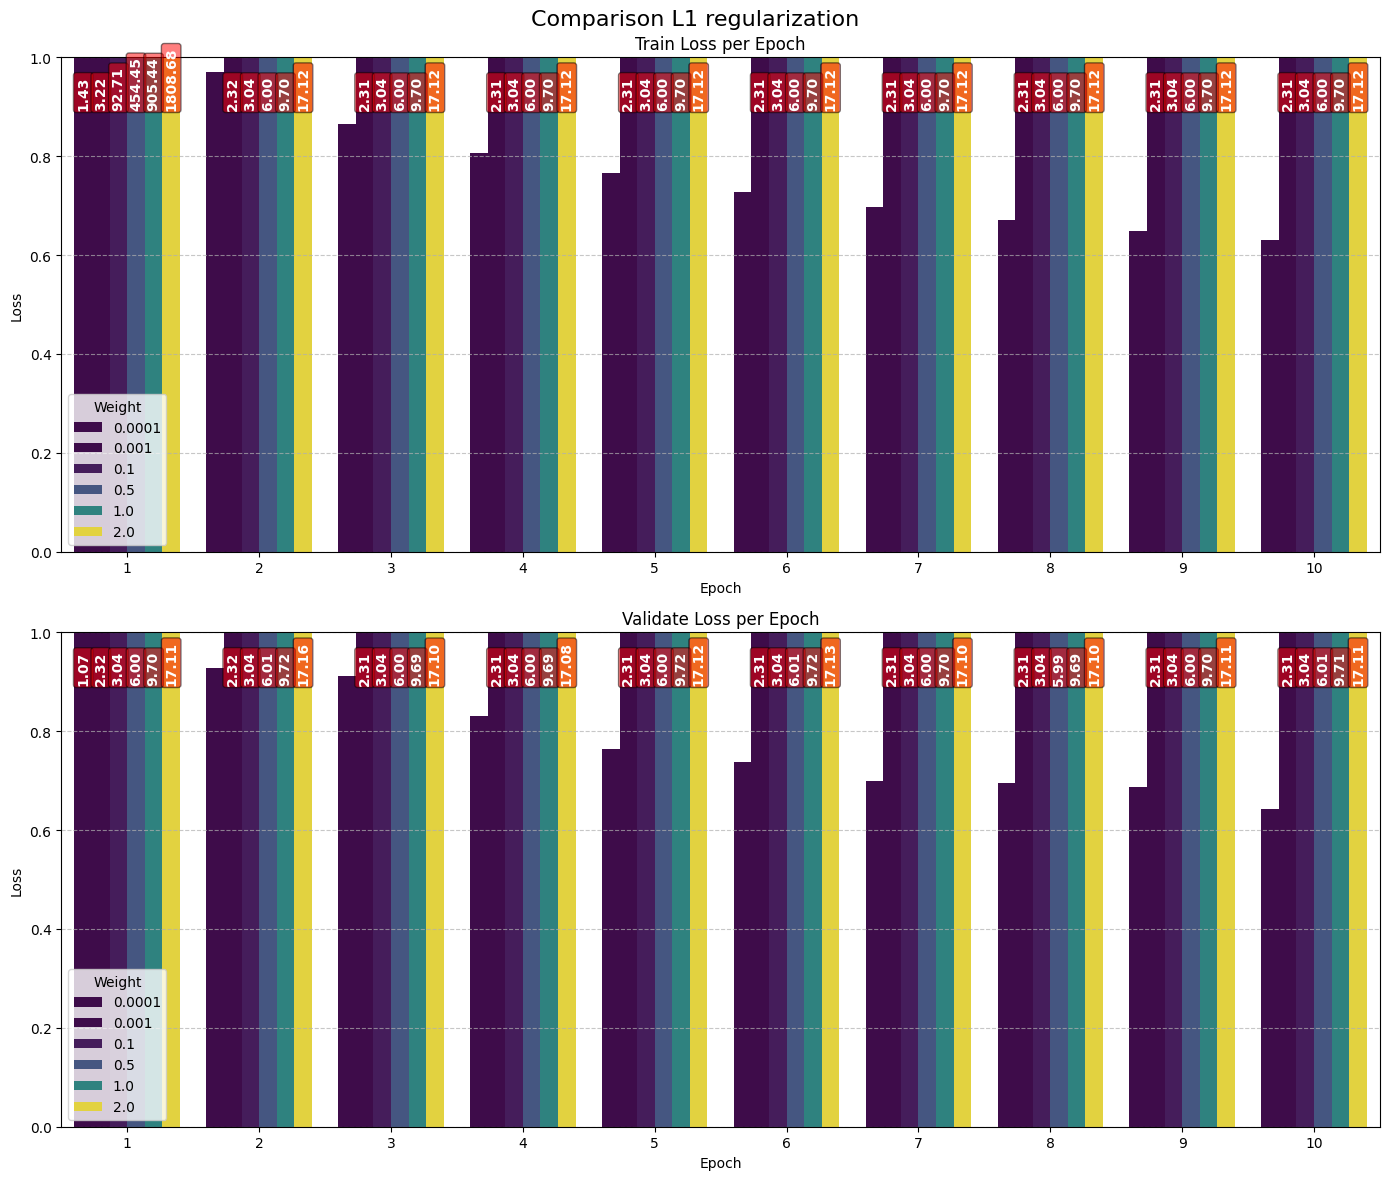

In [119]:
plot_results(train_loss_values, validate_loss_values, 'Comparison L1 regularization')

In [120]:
name = 'L1 '

for i in train_loss_values.keys():
    key_name = name + str(i)
    all_loses[key_name] = {'train': train_loss_values[i][-1], 'validate': validate_loss_values[i][-1]}

In [121]:
all_loses

{'Standart': {'train': np.float64(0.2227571485122045),
  'validate': np.float64(0.3210475484182121)},
 'L1 0.0001': {'train': np.float64(0.6295609521071116),
  'validate': np.float64(0.6432554342184856)},
 'L1 0.001': {'train': np.float64(2.3097666895548503),
  'validate': np.float64(2.309696209658483)},
 'L1 0.1': {'train': np.float64(3.0425644026438396),
  'validate': np.float64(3.0438120441072307)},
 'L1 0.5': {'train': np.float64(6.000212708028157),
  'validate': np.float64(6.006527478527871)},
 'L1 1.0': {'train': np.float64(9.702223793538412),
  'validate': np.float64(9.710967622744809)},
 'L1 2.0': {'train': np.float64(17.119057743326824),
  'validate': np.float64(17.11062386385195)}}

<center><h5>L2 регуляризация

Starting epoch 1
Starting epoch 2
Starting epoch 3
Starting epoch 4
Starting epoch 5
Starting epoch 6
Starting epoch 7
Starting epoch 8
Starting epoch 9
Starting epoch 10
Starting epoch 1
Starting epoch 2
Starting epoch 3
Starting epoch 4
Starting epoch 5
Starting epoch 6
Starting epoch 7
Starting epoch 8
Starting epoch 9
Starting epoch 10
Starting epoch 1
Starting epoch 2
Starting epoch 3
Starting epoch 4
Starting epoch 5
Starting epoch 6
Starting epoch 7
Starting epoch 8
Starting epoch 9
Starting epoch 10
Starting epoch 1
Starting epoch 2
Starting epoch 3
Starting epoch 4
Starting epoch 5
Starting epoch 6
Starting epoch 7
Starting epoch 8
Starting epoch 9
Starting epoch 10
Starting epoch 1
Starting epoch 2
Starting epoch 3
Starting epoch 4
Starting epoch 5
Starting epoch 6
Starting epoch 7
Starting epoch 8
Starting epoch 9
Starting epoch 10
Starting epoch 1
Starting epoch 2
Starting epoch 3
Starting epoch 4
Starting epoch 5
Starting epoch 6
Starting epoch 7
Starting epoch 8
Starting 

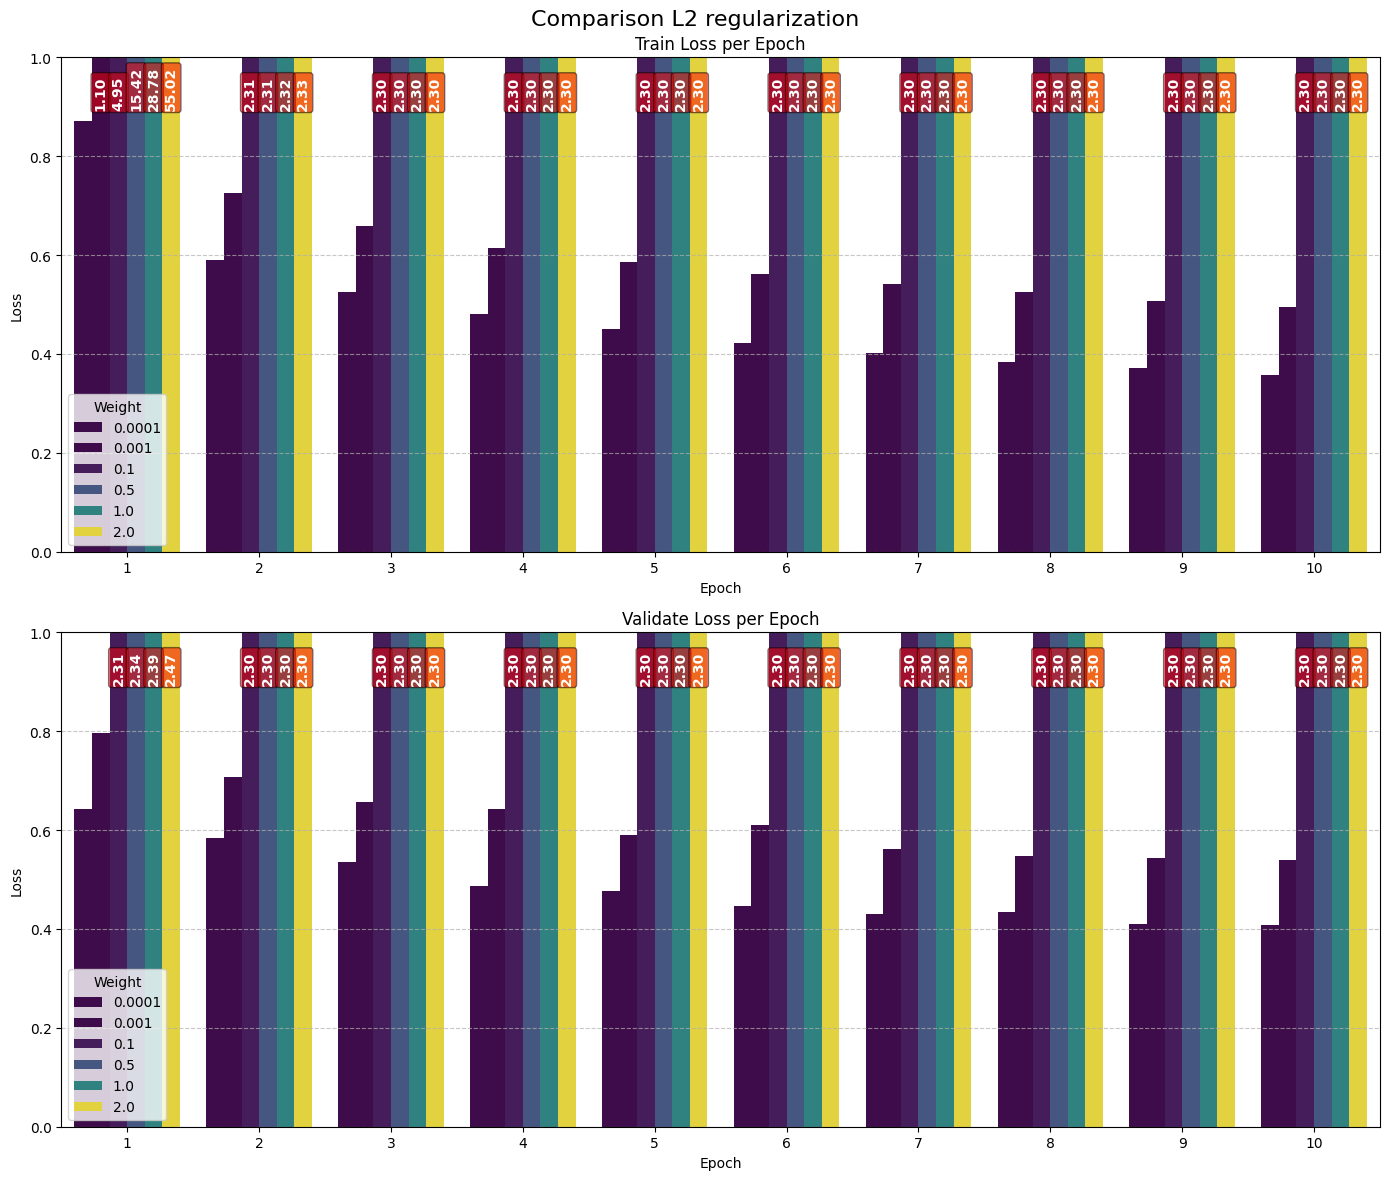

TypeError: can only concatenate str (not "float") to str

In [ ]:
grid = [1e-4, 1e-3, 0.1, 0.5, 1.0, 2.0]
train_loss_values = {}
validate_loss_values = {}
for weight in grid:
    model = MLP()
    model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
    current_train_losses = []
    current_valid_losses = []
    for epoch in range(EPOCHS):
        model.train()
        train_loss = []
        valid_loss = []
        print(f'Starting epoch {epoch + 1}')
        for data, targets in train_loader:
            data, targets = data.to(device), targets.to(device)
            optimizer.zero_grad()
            outputs = model(data)
            loss = criterion(outputs, targets)
            l2_weight = weight
            l2_parameters = []
            for parameter in model.parameters():
                l2_parameters.append(parameter.view(-1))
            l2 = l2_weight * model.compute_l2_loss(torch.cat(l2_parameters))
            loss += l2
            loss.backward()
            optimizer.step()
            train_loss.append(loss.item())

        model.eval()
        with torch.inference_mode():
            for data, targets in valid_loader:
                data, targets = data.to(device), targets.to(device)
                outputs = model(data)
                loss = criterion(outputs, targets)
                l2_weight = weight
                l2_parameters = []
                for parameter in model.parameters():
                    l2_parameters.append(parameter.view(-1))
                l2 = l2_weight * model.compute_l2_loss(torch.cat(l2_parameters))
                loss += l2
                valid_loss.append(loss.item())
                # print(f'Epoch {epoch + 1} train loss: {np.mean(train_loss)} validation loss: {np.mean(valid_loss)}')
        current_train_losses.append(np.mean(train_loss))
        current_valid_losses.append(np.mean(valid_loss))
    train_loss_values[weight] = current_train_losses
    validate_loss_values[weight] = current_valid_losses

plot_results(train_loss_values, validate_loss_values, 'Comparison L2 regularization')

In [123]:

name = 'L2 '

for i in train_loss_values.keys():
    key_name = name + str(i)
    all_loses[key_name] = {'train': train_loss_values[i][-1], 'validate': validate_loss_values[i][-1]}

<center><h5>ElasticNet регуляризация

Starting epoch 1
Starting epoch 2
Starting epoch 3
Starting epoch 4
Starting epoch 5
Starting epoch 6
Starting epoch 7
Starting epoch 8
Starting epoch 9
Starting epoch 10
Starting epoch 1
Starting epoch 2
Starting epoch 3
Starting epoch 4
Starting epoch 5
Starting epoch 6
Starting epoch 7
Starting epoch 8
Starting epoch 9
Starting epoch 10
Starting epoch 1
Starting epoch 2
Starting epoch 3
Starting epoch 4
Starting epoch 5
Starting epoch 6
Starting epoch 7
Starting epoch 8
Starting epoch 9
Starting epoch 10
Starting epoch 1
Starting epoch 2
Starting epoch 3
Starting epoch 4
Starting epoch 5
Starting epoch 6
Starting epoch 7
Starting epoch 8
Starting epoch 9
Starting epoch 10
Starting epoch 1
Starting epoch 2
Starting epoch 3
Starting epoch 4
Starting epoch 5
Starting epoch 6
Starting epoch 7
Starting epoch 8
Starting epoch 9
Starting epoch 10


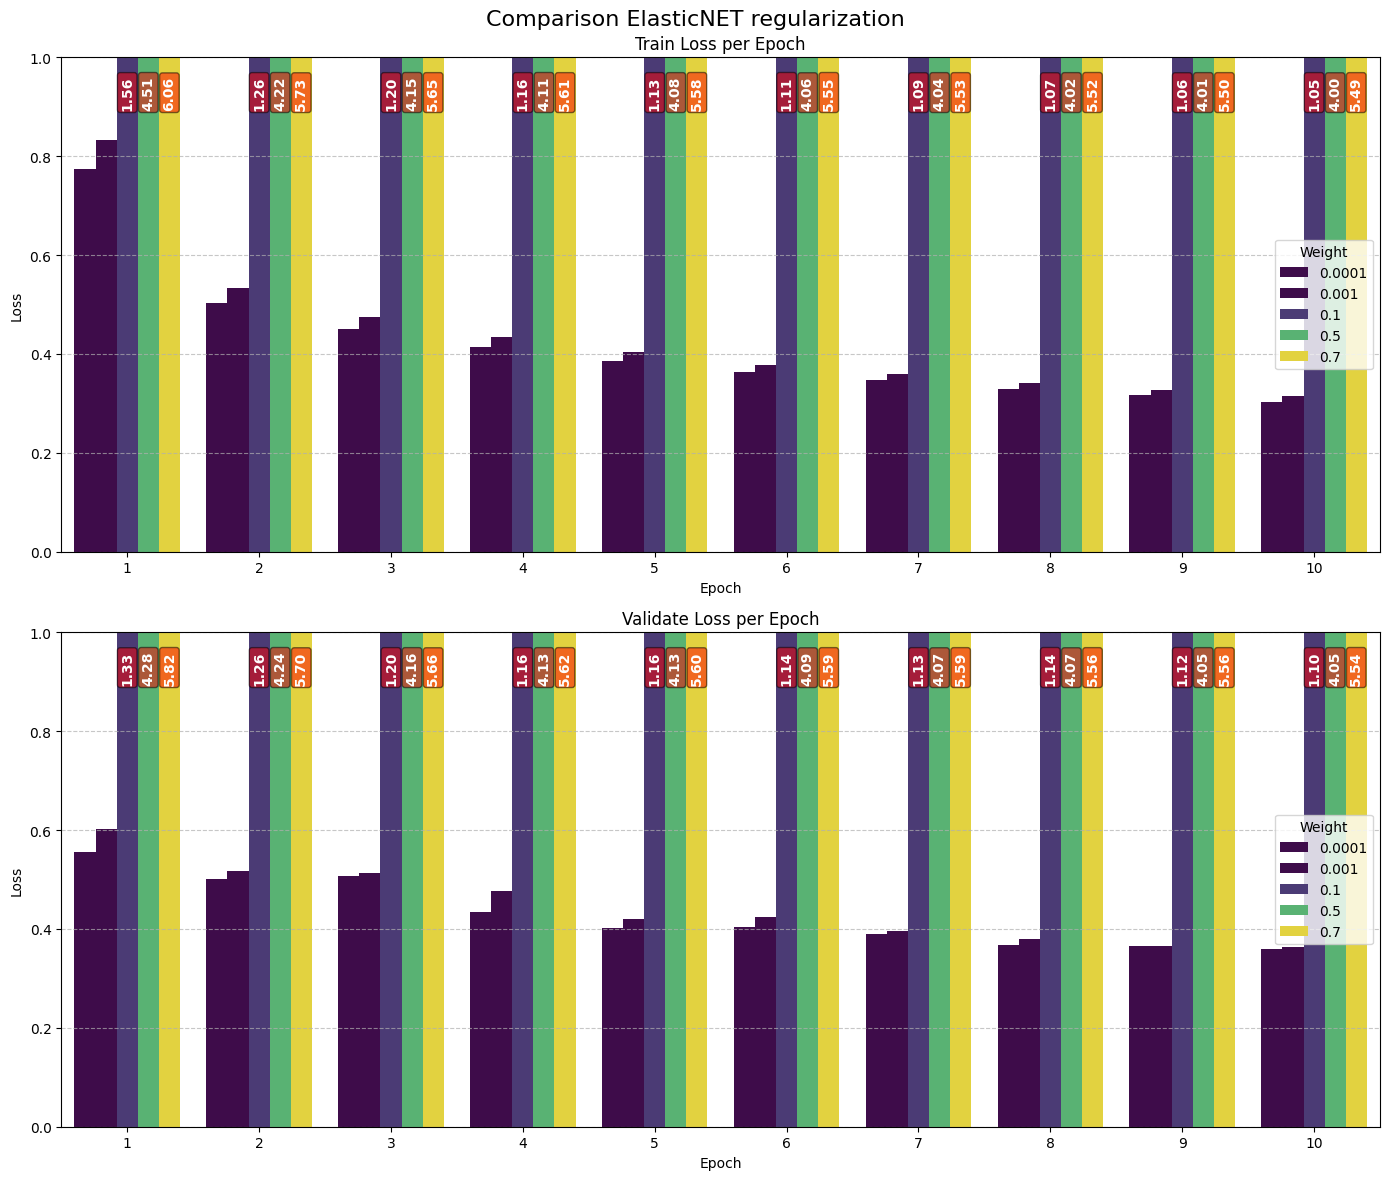

In [124]:
grid = [1e-4, 1e-3, 0.1, 0.5, 0.7]
train_loss_values = {}
validate_loss_values = {}
for weight in grid:
    model = MLP()
    model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
    current_train_losses = []
    current_valid_losses = []
    for epoch in range(EPOCHS):
        model.train()
        train_loss = []
        valid_loss = []
        print(f'Starting epoch {epoch + 1}')
        for data, targets in train_loader:
            data, targets = data.to(device), targets.to(device)
            optimizer.zero_grad()
            outputs = model(data)
            loss = criterion(outputs, targets)
            l1_weight = weight
            l2_weight = 1 - weight
            parameters = []
            for parameter in model.parameters():
                parameters.append(parameter.view(-1))
            l1 = l1_weight * model.compute_l1_loss(torch.cat(l1_parameters))
            l2 = l2_weight * model.compute_l2_loss(torch.cat(l2_parameters))
            loss += l2
            loss += l1
            loss.backward()
            optimizer.step()
            train_loss.append(loss.item())

        model.eval()
        with torch.inference_mode():
            for data, targets in valid_loader:
                data, targets = data.to(device), targets.to(device)
                outputs = model(data)
                loss = criterion(outputs, targets)
                l1_weight = weight
                l2_weight = 1 - weight
                parameters = []
                for parameter in model.parameters():
                    parameters.append(parameter.view(-1))
                l1 = l1_weight * model.compute_l1_loss(torch.cat(l1_parameters))
                l2 = l2_weight * model.compute_l2_loss(torch.cat(l2_parameters))
                loss += l2
                loss += l1
                valid_loss.append(loss.item())
                # print(f'Epoch {epoch + 1} train loss: {np.mean(train_loss)} validation loss: {np.mean(valid_loss)}')
        current_train_losses.append(np.mean(train_loss))
        current_valid_losses.append(np.mean(valid_loss))
    train_loss_values[weight] = current_train_losses
    validate_loss_values[weight] = current_valid_losses

plot_results(train_loss_values, validate_loss_values, 'Comparison ElasticNET regularization')

name = 'ElasticNet '

for i in train_loss_values.keys():
    key_name = name + str(i)
    all_loses[key_name] = {'train': train_loss_values[i][-1], 'validate': validate_loss_values[i][-1]}

<center><h5>Dropout регуляризация

In [125]:
class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.layer1 = nn.Linear(28 * 28 * 1, 512)
        self.layer2 = nn.Linear(512, 256)
        self.layer3 = nn.Linear(256, 128)
        self.layer4 = nn.Linear(128, 64)
        self.layer5 = nn.Linear(64, 32)
        self.layer6 = nn.Linear(32, 10)
        self.activation = nn.ReLU()
        self.flatten = nn.Flatten()
        self.dropout3 = nn.Dropout(p=.3)
        self.dropout1 = nn.Dropout(p=.1)

    def forward(self, x):
        x = self.activation(self.layer1(self.flatten(x)))
        x = self.dropout1(self.activation(self.layer2(x)))
        x = self.activation(self.layer3(x))
        x = self.dropout3(self.activation(self.layer4(x)))
        x = self.activation(self.layer5(x))
        x = self.layer6(x)
        return x

In [126]:
model = MLP()
model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
current_train_losses = []
current_valid_losses = []
for epoch in range(EPOCHS):
    model.train()
    train_loss = []
    valid_loss = []
    print(f'Starting epoch {epoch + 1}')
    for data, targets in train_loader:
        data, targets = data.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = model(data)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        train_loss.append(loss.item())

    model.eval()
    with torch.inference_mode():
        for data, targets in valid_loader:
            data, targets = data.to(device), targets.to(device)
            outputs = model(data)
            loss = criterion(outputs, targets)
            valid_loss.append(loss.item())
            print(f'Epoch {epoch + 1} train loss: {np.mean(train_loss)} validation loss: {np.mean(valid_loss)}')

all_loses['Dropout'] = {'train': np.mean(train_loss), 'validate': np.mean(valid_loss)}


Starting epoch 1
Epoch 1 train loss: 0.9021452715873718 validation loss: 0.6636072993278503
Epoch 1 train loss: 0.9021452715873718 validation loss: 0.5239934921264648
Epoch 1 train loss: 0.9021452715873718 validation loss: 0.506969153881073
Epoch 1 train loss: 0.9021452715873718 validation loss: 0.5035553127527237
Epoch 1 train loss: 0.9021452715873718 validation loss: 0.507716977596283
Epoch 1 train loss: 0.9021452715873718 validation loss: 0.4983411480983098
Epoch 1 train loss: 0.9021452715873718 validation loss: 0.5027463223252978
Epoch 1 train loss: 0.9021452715873718 validation loss: 0.5163119472563267
Epoch 1 train loss: 0.9021452715873718 validation loss: 0.5175148944060007
Epoch 1 train loss: 0.9021452715873718 validation loss: 0.5329348593950272
Epoch 1 train loss: 0.9021452715873718 validation loss: 0.5437248159538616
Epoch 1 train loss: 0.9021452715873718 validation loss: 0.555919366578261
Epoch 1 train loss: 0.9021452715873718 validation loss: 0.5525628121999594
Epoch 1 tra

<center><h5>BatchNorm регуляризация

In [127]:
class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.layer1 = nn.Linear(28 * 28 * 1, 512)
        self.layer2 = nn.Linear(512, 256)
        self.bn2 = nn.BatchNorm1d(256)
        self.layer3 = nn.Linear(256, 128)
        self.bn3 = nn.BatchNorm1d(128)
        self.layer4 = nn.Linear(128, 64)
        self.layer5 = nn.Linear(64, 32)
        self.layer6 = nn.Linear(32, 10)
        self.activation = nn.ReLU()
        self.flatten = nn.Flatten()

    def forward(self, x):
        x = self.activation(self.layer1(self.flatten(x)))
        x = self.bn2(self.activation(self.layer2(x)))
        x = self.bn3(self.activation(self.layer3(x)))
        x = self.activation(self.layer4(x))
        x = self.activation(self.layer5(x))
        x = self.layer6(x)
        return x

In [128]:
model = MLP()
model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

for epoch in range(EPOCHS):
    model.train()
    train_loss = []
    valid_loss = []
    print(f'Starting epoch {epoch + 1}')
    for data, targets in train_loader:
        data, targets = data.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = model(data)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        train_loss.append(loss.item())

    model.eval()
    with torch.inference_mode():
        for data, targets in valid_loader:
            data, targets = data.to(device), targets.to(device)
            outputs = model(data)
            loss = criterion(outputs, targets)
            valid_loss.append(loss.item())
            print(f'Epoch {epoch + 1} train loss: {np.mean(train_loss)} validation loss: {np.mean(valid_loss)}')

all_loses['BatchNorm'] = {'train': np.mean(train_loss), 'validate': np.mean(valid_loss)}

Starting epoch 1
Epoch 1 train loss: 0.6516596958875656 validation loss: 0.5009635090827942
Epoch 1 train loss: 0.6516596958875656 validation loss: 0.4161631613969803
Epoch 1 train loss: 0.6516596958875656 validation loss: 0.4094808300336202
Epoch 1 train loss: 0.6516596958875656 validation loss: 0.402821309864521
Epoch 1 train loss: 0.6516596958875656 validation loss: 0.39947794675827025
Epoch 1 train loss: 0.6516596958875656 validation loss: 0.4046187698841095
Epoch 1 train loss: 0.6516596958875656 validation loss: 0.4054931402206421
Epoch 1 train loss: 0.6516596958875656 validation loss: 0.41698363423347473
Epoch 1 train loss: 0.6516596958875656 validation loss: 0.4182269308302138
Epoch 1 train loss: 0.6516596958875656 validation loss: 0.42371739745140075
Epoch 1 train loss: 0.6516596958875656 validation loss: 0.4380330280824141
Epoch 1 train loss: 0.6516596958875656 validation loss: 0.44242461522420246
Epoch 1 train loss: 0.6516596958875656 validation loss: 0.4387471263225262
Epoch

In [ ]:
outputs, targets = inference(model, valid_loader)


In [130]:
for o, t in zip(outputs, targets):
    print(f"{o.item()} -> {t.item()}")

9 -> 9
2 -> 2
1 -> 1
1 -> 1
6 -> 6
1 -> 1
4 -> 4
6 -> 6
5 -> 5
7 -> 7
4 -> 4
5 -> 5
5 -> 7
3 -> 3
4 -> 4
1 -> 1
2 -> 2
2 -> 4
8 -> 8
0 -> 0
2 -> 2
5 -> 5
7 -> 7
5 -> 9
1 -> 1
2 -> 4
6 -> 6
0 -> 0
9 -> 9
6 -> 3
8 -> 8
8 -> 8
3 -> 3
3 -> 3
8 -> 8
0 -> 0
7 -> 7
5 -> 5
7 -> 7
9 -> 9
0 -> 6
1 -> 1
6 -> 3
7 -> 7
6 -> 6
7 -> 7
2 -> 2
1 -> 1
2 -> 2
6 -> 2
4 -> 4
2 -> 4
5 -> 5
8 -> 8
2 -> 2
2 -> 2
8 -> 8
4 -> 4
8 -> 8
0 -> 0
7 -> 7
7 -> 7
8 -> 8
5 -> 5


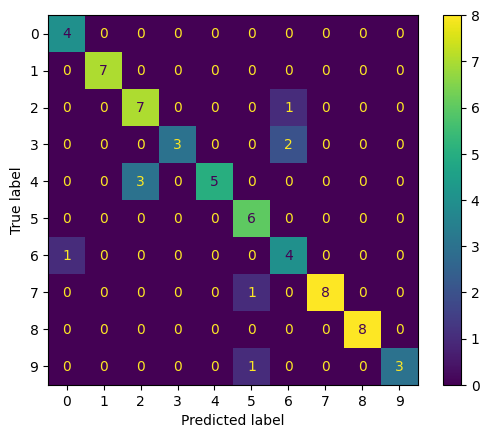

In [157]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(targets.to('cpu'), outputs.to('cpu'))
plt.show()

In [158]:
class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.layer1 = nn.Linear(28 * 28 * 1, 512)
        self.layer2 = nn.Linear(512, 256)
        self.bn2 = nn.BatchNorm1d(256)
        self.layer3 = nn.Linear(256, 128)
        self.bn3 = nn.BatchNorm1d(128)
        self.layer4 = nn.Linear(128, 64)
        self.bn4 = nn.BatchNorm1d(64)
        self.layer5 = nn.Linear(64, 32)
        self.bn5 = nn.BatchNorm1d(32)
        self.layer6 = nn.Linear(32, 10)
        self.activation = nn.ReLU()
        self.flatten = nn.Flatten()

    def forward(self, x):
        x = self.activation(self.layer1(self.flatten(x)))
        x = self.bn2(self.activation(self.layer2(x)))
        x = self.bn3(self.activation(self.layer3(x)))
        x = self.bn4(self.activation(self.layer4(x)))
        x = self.bn5(self.activation(self.layer5(x)))
        x = self.layer6(x)
        return x
    
model = MLP()
model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

for epoch in range(EPOCHS):
    model.train()
    train_loss = []
    valid_loss = []
    print(f'Starting epoch {epoch + 1}')
    for data, targets in train_loader:
        data, targets = data.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = model(data)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        train_loss.append(loss.item())

    model.eval()
    with torch.inference_mode():
        for data, targets in valid_loader:
            data, targets = data.to(device), targets.to(device)
            outputs = model(data)
            loss = criterion(outputs, targets)
            valid_loss.append(loss.item())
            print(f'Epoch {epoch + 1} train loss: {np.mean(train_loss)} validation loss: {np.mean(valid_loss)}')

all_loses['BatchNormAll'] = {'train': np.mean(train_loss), 'validate': np.mean(valid_loss)}


Starting epoch 1
Epoch 1 train loss: 0.6900828875064849 validation loss: 0.48144370317459106
Epoch 1 train loss: 0.6900828875064849 validation loss: 0.42337289452552795
Epoch 1 train loss: 0.6900828875064849 validation loss: 0.4267667929331462
Epoch 1 train loss: 0.6900828875064849 validation loss: 0.44246554374694824
Epoch 1 train loss: 0.6900828875064849 validation loss: 0.4212617576122284
Epoch 1 train loss: 0.6900828875064849 validation loss: 0.4347517242034276
Epoch 1 train loss: 0.6900828875064849 validation loss: 0.43475848010608126
Epoch 1 train loss: 0.6900828875064849 validation loss: 0.445684764534235
Epoch 1 train loss: 0.6900828875064849 validation loss: 0.4502844479348924
Epoch 1 train loss: 0.6900828875064849 validation loss: 0.46017906665802
Epoch 1 train loss: 0.6900828875064849 validation loss: 0.46720684658397327
Epoch 1 train loss: 0.6900828875064849 validation loss: 0.4738200058539708
Epoch 1 train loss: 0.6900828875064849 validation loss: 0.4695605222995465
Epoch 

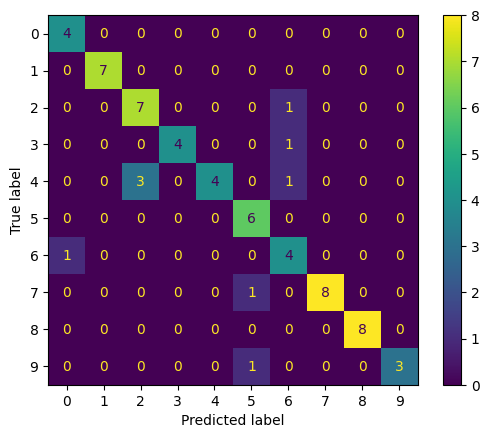

In [159]:
outputs, targets = inference(model, valid_loader)

ConfusionMatrixDisplay.from_predictions(targets.to('cpu'), outputs.to('cpu'))
plt.show()

In [160]:
all_loses

{'Standart': {'train': np.float64(0.2227571485122045),
  'validate': np.float64(0.3210475484182121)},
 'L1 0.0001': {'train': np.float64(0.6295609521071116),
  'validate': np.float64(0.6432554342184856)},
 'L1 0.001': {'train': np.float64(2.3097666895548503),
  'validate': np.float64(2.309696209658483)},
 'L1 0.1': {'train': np.float64(3.0425644026438396),
  'validate': np.float64(3.0438120441072307)},
 'L1 0.5': {'train': np.float64(6.000212708028157),
  'validate': np.float64(6.006527478527871)},
 'L1 1.0': {'train': np.float64(9.702223793538412),
  'validate': np.float64(9.710967622744809)},
 'L1 2.0': {'train': np.float64(17.119057743326824),
  'validate': np.float64(17.11062386385195)},
 'L2 0.0001': {'train': np.float64(0.356827744781971),
  'validate': np.float64(0.40821031732544016)},
 'L2 0.001': {'train': np.float64(0.4957156033118566),
  'validate': np.float64(0.5398221634755469)},
 'L2 0.1': {'train': np.float64(2.3026094441731773),
  'validate': np.float64(2.30258690931235

<center><h3>Результат

{'Standart': np.float64(0.2227571485122045), 'L1 0.0001': np.float64(0.6295609521071116), 'L1 0.001': np.float64(2.3097666895548503), 'L1 0.1': np.float64(3.0425644026438396), 'L1 0.5': np.float64(6.000212708028157), 'L1 1.0': np.float64(9.702223793538412), 'L1 2.0': np.float64(17.119057743326824), 'L2 0.0001': np.float64(0.356827744781971), 'L2 0.001': np.float64(0.4957156033118566), 'L2 0.1': np.float64(2.3026094441731773), 'L2 0.5': np.float64(2.302605774943034), 'L2 1.0': np.float64(2.302603519821167), 'L2 2.0': np.float64(2.3026096983591717), 'ElasticNet 0.0001': np.float64(0.30230372931162514), 'ElasticNet 0.001': np.float64(0.31559578810135525), 'ElasticNet 0.1': np.float64(1.0468185855547587), 'ElasticNet 0.5': np.float64(3.995523647816976), 'ElasticNet 0.7': np.float64(5.493547355397542), 'Dropout': np.float64(0.3174407444338004), 'BatchNorm': np.float64(0.23270477630595365), 'BatchNormAll': np.float64(0.2486262051562468)}


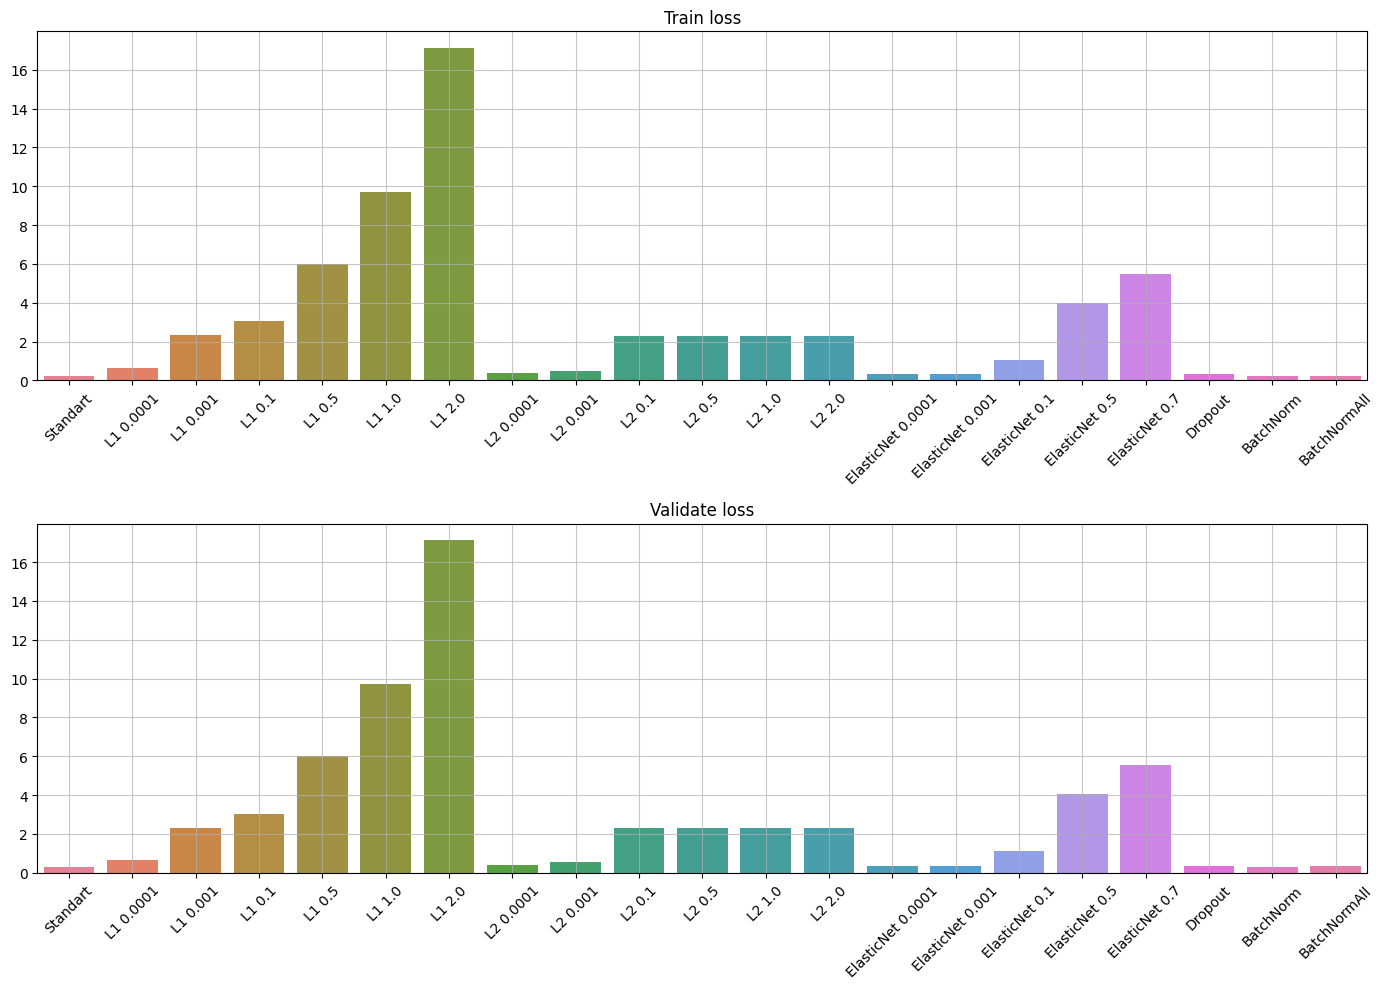

In [161]:
fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(14, 10))


data_train_loss, data_validate_loss = {}, {}
for name, data in all_loses.items():
    data_train_loss[name] = data['train']
    data_validate_loss[name] = data['validate']

print(data_train_loss)
df_train_loss = pd.DataFrame(data_train_loss, index=data_train_loss.keys())
df_validate_loss = pd.DataFrame(data_validate_loss, index=data_validate_loss.keys())

plt.title('Comparison result of regularisation methods')
sns.barplot(df_train_loss, ax=ax1)
ax1.set_title('Train loss')
ax1.grid(True, alpha=.7)
ax1.tick_params(axis='x', rotation=45)
sns.barplot(df_validate_loss, ax=ax2)
ax2.set_title('Validate loss')
ax2.grid(True, alpha=.7)
ax2.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


<center><h1>С небольшим отрывом побеждает BatchNorm*</h1> 
<text>*Не учитывая, что у Standart результат лучше, но там и 20 итераций</text>

In [10]:
class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.layer1 = nn.Linear(28 * 28 * 1, 2048)
        self.layer2 = nn.Linear(2048, 1024)
        self.layer3 = nn.Linear(1024, 512)
        self.layer4 = nn.Linear(512, 256)
        self.layer5 = nn.Linear(256, 128)
        self.layer6 = nn.Linear(128, 64)
        self.layer7 = nn.Linear(64, 32)
        self.layer8 = nn.Linear(32, 10)
        self.activation = nn.LogSigmoid()
        self.flatten = nn.Flatten()

    def forward(self, x):
        x = self.activation(self.layer1(self.flatten(x)))
        x = self.activation(self.layer2(x))
        x = self.activation(self.layer3(x))
        x = self.activation(self.layer4(x))
        x = self.activation(self.layer5(x))
        x = self.activation(self.layer6(x))
        x = self.activation(self.layer7(x))
        x = self.layer8(x)
        return x

In [11]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)
model_9layer = MLP()
model_9layer.to(device)

cuda


MLP(
  (layer1): Linear(in_features=784, out_features=2048, bias=True)
  (layer2): Linear(in_features=2048, out_features=1024, bias=True)
  (layer3): Linear(in_features=1024, out_features=512, bias=True)
  (layer4): Linear(in_features=512, out_features=256, bias=True)
  (layer5): Linear(in_features=256, out_features=128, bias=True)
  (layer6): Linear(in_features=128, out_features=64, bias=True)
  (layer7): Linear(in_features=64, out_features=32, bias=True)
  (layer8): Linear(in_features=32, out_features=10, bias=True)
  (activation): LogSigmoid()
  (flatten): Flatten(start_dim=1, end_dim=-1)
)

In [12]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_9layer.parameters(), lr=1e-4)

In [13]:
import numpy as np


EPOCHS = 10

for epoch in range(EPOCHS):
    print('Starting epoch: ', epoch + 1)
    model_9layer.train()
    train_loss = []
    valid_loss = []
    for data, targets in train_loader:
        data, targets = data.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = model_9layer(data)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        train_loss.append(loss.item())

    model_9layer.eval()
    with torch.inference_mode():
        for data, targets in valid_loader:
            data, targets = data.to(device), targets.to(device)
            outputs = model_9layer(data)
            loss = criterion(outputs, targets)
            valid_loss.append(loss.item())
            print(f'Epoch {epoch + 1} train loss: {np.mean(train_loss)} validation loss: {np.mean(valid_loss)}')


Starting epoch:  1
Epoch 1 train loss: 0.9409524662256241 validation loss: 0.7635673880577087
Epoch 1 train loss: 0.9409524662256241 validation loss: 0.6501025855541229
Epoch 1 train loss: 0.9409524662256241 validation loss: 0.6216387152671814
Epoch 1 train loss: 0.9409524662256241 validation loss: 0.6101085394620895
Epoch 1 train loss: 0.9409524662256241 validation loss: 0.6072020649909973
Epoch 1 train loss: 0.9409524662256241 validation loss: 0.5935116608937582
Epoch 1 train loss: 0.9409524662256241 validation loss: 0.5964066641671317
Epoch 1 train loss: 0.9409524662256241 validation loss: 0.6141418069601059
Epoch 1 train loss: 0.9409524662256241 validation loss: 0.6133189863628812
Epoch 1 train loss: 0.9409524662256241 validation loss: 0.6403388857841492
Epoch 1 train loss: 0.9409524662256241 validation loss: 0.6433582901954651
Epoch 1 train loss: 0.9409524662256241 validation loss: 0.6516469468673071
Epoch 1 train loss: 0.9409524662256241 validation loss: 0.6429635790678171
Epoch 

In [ ]:
all_loses['Standart 8 layers sigmoid'] = {'train': np.mean(train_loss), 'validate': np.mean(valid_loss)}
